# Wafer Guard · Repaired Fab-7 Excursion Detector

This notebook is the **audited and repaired** version of `original/bnypi.ipynb`.

**How to read it.** Every section answers one question, in this order:

| § | Question | Phase |
|---|---|---|
| 1 | What does the data actually contain? | Understand |
| 2 | Does the original really score F1 ≥ 0.90? | Reproduce |
| 3 | *Why* does it score that high? (evidence for every defect) | Audit |
| 4 | How do we build a pipeline that respects time and tensor shapes? | Repair |
| 5 | What is the honest performance at natural defect prevalence? | Re-evaluate |
| 6 | Does that hold up across time (walk-forward)? | Re-evaluate |
| 7 | How much of the fake 0.90 does each bug explain? | Attribute |
| 8 | One table: original vs repaired vs baselines | Summarise |
| 9 | Save artifacts + every measured number to `results/metrics.json` | Ship |

**Rule followed throughout:** no number in this project is typed by hand.
Every metric is computed in a cell below and written to `results/metrics.json`;
`AUDIT.md` and the Release Board app read their numbers from that file.

## 0 · Setup

Same libraries and **the same hyper-parameters as the original** (`HP` is copied unchanged).
We deliberately do *not* tune the model: the goal is to fix defects, so any change in the
score can be attributed to a fix, not to tuning.

In [1]:
import json
import random
import warnings
from dataclasses import dataclass, replace
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 1337                                   # same seed as the original notebook
EVAL_SEEDS = [1337, 7, 42, 2024, 31337]       # extra seeds, to show run-to-run variation


def set_seed(seed: int) -> None:
    """Make numpy, python and torch random numbers repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Unchanged from the original notebook.
HP = dict(batch_size=64, epochs=40, lr=1e-3, weight_decay=1e-5,
          hidden=256, latent=32, lambda_clf=1.0, test_size=0.20)

# New settings introduced by the repair (chosen up-front, never tuned on the test set).
SPLIT_FRACTIONS = dict(train=0.60, val=0.20)  # test = the most recent 20 % of wafers
CLIP_Z = 5.0          # cap standardised values at ±5σ (see §4.2 for why)
LEGACY_CODES = (100.0, 200.0, 300.0)          # PS-L firmware error codes (from the brief)
GATE_F1 = 0.90        # the release gate used by the original notebook

DATA_PATH = Path("data/secom_telemetry_modified.csv")
RESULTS_DIR = Path("results")
FIG_DIR = RESULTS_DIR / "figures"
ARTIFACT_DIR = Path("artifacts")
for d in (RESULTS_DIR, FIG_DIR, ARTIFACT_DIR):
    d.mkdir(parents=True, exist_ok=True)

RESULTS: dict = {}    # every measured number is collected here and saved in §9
print(f"torch {torch.__version__} | device={DEVICE}")

torch 2.10.0+cpu | device=cpu


Chart styling (one shared look for every figure: thin marks, quiet grid, a fixed colour order).

In [2]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BLUES = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titleweight": "semibold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
})


def save_fig(fig, name: str) -> None:
    """Save a figure to results/figures/<name>.png and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1 · The data

We sort by `timestamp` because the fab is a time series: in production the model only
ever sees wafers from the past.

In [3]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)

SENSOR_COLS = [c for c in df.columns if c.startswith("sensor_")]
y_all = (df["label"].to_numpy() == 1).astype(np.int64)        # 1 = defective wafer
TS = df["timestamp"].to_numpy()

RESULTS["data"] = dict(
    n_wafers=len(df), n_sensors=len(SENSOR_COLS),
    n_fail=int(y_all.sum()), n_pass=int((1 - y_all).sum()),
    prevalence=float(y_all.mean()),
    missing_rate=float(df[SENSOR_COLS].isna().to_numpy().mean()),
    n_constant_sensors=int((df[SENSOR_COLS].nunique(dropna=True) <= 1).sum()),
    time_start=str(df["timestamp"].min()), time_end=str(df["timestamp"].max()),
)
print(json.dumps(RESULTS["data"], indent=2))

{
  "n_wafers": 1567,
  "n_sensors": 590,
  "n_fail": 104,
  "n_pass": 1463,
  "prevalence": 0.06636885768985322,
  "missing_rate": 0.045372243193839035,
  "n_constant_sensors": 116,
  "time_start": "2008-07-19 11:55:00",
  "time_end": "2008-10-17 06:07:00"
}


### 1.1 · The legacy Probe Station PS-L

The brief says: on PS-L wafers `sensor_0` is exactly `0.0` (a *sentinel*, not a measurement)
and `sensor_1` holds firmware **error codes** 100 / 200 / 300 instead of a real reading.
Before trusting that, we check it against the data.

In [4]:
is_legacy_all = df["sensor_0"].eq(0.0).to_numpy()
s1 = df["sensor_1"]
code_mask = s1.isin(LEGACY_CODES).to_numpy()

legacy = dict(
    n_legacy=int(is_legacy_all.sum()),
    share_legacy=float(is_legacy_all.mean()),
    code_counts={str(int(c)): int((is_legacy_all & (s1 == c)).sum()) for c in LEGACY_CODES},
    codes_outside_legacy=int((code_mask & ~is_legacy_all).sum()),
    legacy_rows_without_code=int((is_legacy_all & ~code_mask).sum()),
    sensor_1_normal_min=float(s1[~is_legacy_all].min()),
    sensor_1_normal_max=float(s1[~is_legacy_all].max()),
    sensor_1_normal_mean=float(s1[~is_legacy_all].mean()),
    fails_in_legacy=int(y_all[is_legacy_all].sum()),
    fails_in_normal=int(y_all[~is_legacy_all].sum()),
    defect_rate_legacy=float(y_all[is_legacy_all].mean()),
    defect_rate_normal=float(y_all[~is_legacy_all].mean()),
)
RESULTS["legacy"] = legacy
print(json.dumps(legacy, indent=2))

# The brief's rule must hold exactly, otherwise our handling would be wrong.
assert legacy["codes_outside_legacy"] == 0, "error codes found on non-legacy wafers"
assert legacy["legacy_rows_without_code"] == 0, "legacy wafer without an error code"

{
  "n_legacy": 146,
  "share_legacy": 0.09317166560306318,
  "code_counts": {
    "100": 61,
    "200": 35,
    "300": 50
  },
  "codes_outside_legacy": 0,
  "legacy_rows_without_code": 0,
  "sensor_1_normal_min": 2158.75,
  "sensor_1_normal_max": 2846.44,
  "sensor_1_normal_mean": 2495.6859562455893,
  "fails_in_legacy": 0,
  "fails_in_normal": 104,
  "defect_rate_legacy": 0.0,
  "defect_rate_normal": 0.07318789584799437
}


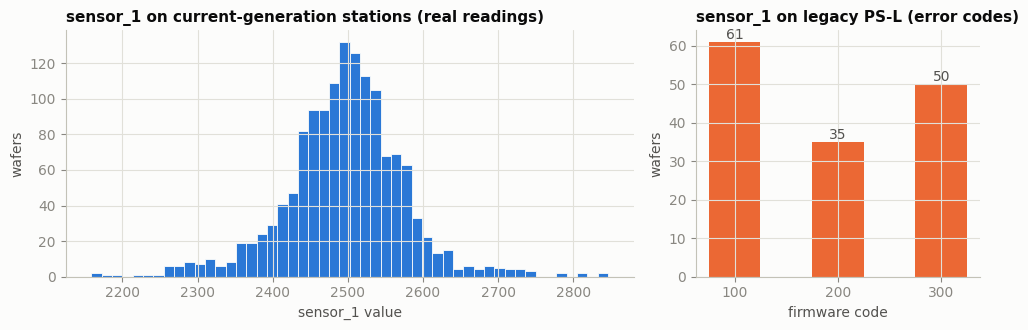

In [5]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2, 1]})
ax_a.hist(s1[~is_legacy_all].dropna(), bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax_a.set_title("sensor_1 on current-generation stations (real readings)")
ax_a.set_xlabel("sensor_1 value"); ax_a.set_ylabel("wafers")
codes = list(legacy["code_counts"].keys())
ax_b.bar(codes, list(legacy["code_counts"].values()), color=ORANGE, width=0.5)
for i, v in enumerate(legacy["code_counts"].values()):
    ax_b.text(i, v, f"{v}", ha="center", va="bottom", color=INK_2)
ax_b.set_title("sensor_1 on legacy PS-L (error codes)")
ax_b.set_xlabel("firmware code"); ax_b.set_ylabel("wafers")
fig.tight_layout()
save_fig(fig, "01_legacy_sensor_1")

**Reading the chart.** Real `sensor_1` readings live in a narrow band in the thousands;
PS-L wafers report one of three codes. Feeding `100.0` into the same "continuous" column
tells the model these wafers are wildly abnormal, which is false: it is a label, not a size.

Note the printed `defect_rate_legacy` above: we revisit it as a **residual risk** in §5.4.

### 1.2 · Defect rate drifts over time

The brief warns that "equipment ages, recipes drift". A rolling defect rate shows it.

monthly defect rate: {'2008-07': 0.2222, '2008-08': 0.0919, '2008-09': 0.0288, '2008-10': 0.0613}


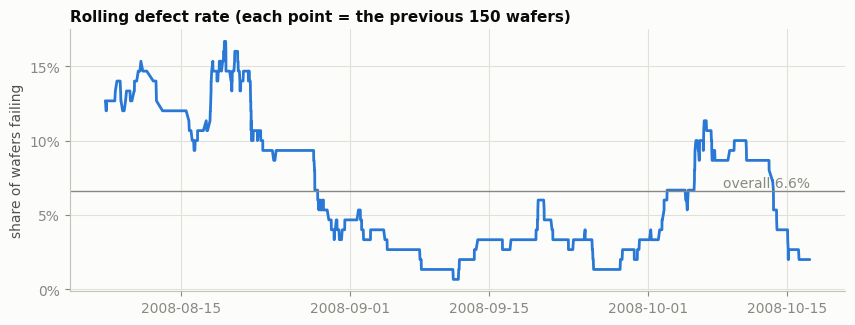

In [6]:
rolling = pd.Series(y_all).rolling(150, min_periods=150).mean()
monthly = df.groupby(df["timestamp"].dt.to_period("M"))["label"].apply(lambda s: float((s == 1).mean()))
RESULTS["data"]["monthly_defect_rate"] = {str(k): v for k, v in monthly.items()}
print("monthly defect rate:", {str(k): round(v, 4) for k, v in monthly.items()})

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(df["timestamp"], rolling, color=BLUE)
ax.axhline(y_all.mean(), color=MUTED, linewidth=1)
ax.text(df["timestamp"].iloc[-1], y_all.mean(), f"overall {y_all.mean():.1%}", ha="right", va="bottom", color=MUTED)
ax.set_title("Rolling defect rate (each point = the previous 150 wafers)")
ax.set_ylabel("share of wafers failing")
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save_fig(fig, "02_defect_rate_drift")

## 2 · Reproduce the original result

Before calling the 0.90 fake we reproduce it. The function below is the original
notebook's cells 8 → 16, **copied verbatim**. The only additions are lines marked
`# + audit` which *record* intermediate objects so §3 can inspect them; they do not
change any computation (`train_test_split` shuffles identically when given one more array).

In [7]:
class WaferSAE(nn.Module):
    """Supervised autoencoder - identical to the original (cell 12)."""

    def __init__(self, d_in: int, d_hid: int, d_lat: int):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(d_in, d_hid), nn.LayerNorm(d_hid), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(d_hid, d_hid // 2), nn.LayerNorm(d_hid // 2), nn.GELU(),
            nn.Linear(d_hid // 2, d_lat),
        )
        self.decoder = nn.Sequential(
            nn.Linear(d_lat, d_hid // 2), nn.GELU(),
            nn.Linear(d_hid // 2, d_hid), nn.GELU(),
            nn.Linear(d_hid, d_in),
        )
        self.head = nn.Linear(d_lat, 1)

    def forward(self, x):
        x = x.flatten(start_dim=1)                       # tolerate [B, F] or [B, C, F]
        z = self.encoder(x)
        return self.decoder(z), self.head(z).squeeze(-1), z


def make_loader(X, y, shuffle, seed=SEED):
    """Identical to the original (cell 10): keeps a channel axis -> [N, 1, F]."""
    Xt = torch.from_numpy(X).float().unsqueeze(1)
    yt = torch.from_numpy(y).float()
    g = torch.Generator().manual_seed(seed)
    return DataLoader(TensorDataset(Xt, yt), batch_size=HP["batch_size"],
                      shuffle=shuffle, generator=g if shuffle else None, drop_last=shuffle)


def run_original_pipeline():
    set_seed(SEED)
    raw = pd.read_csv(DATA_PATH)                                          # file order, as original
    X_raw = raw[SENSOR_COLS].to_numpy(dtype=np.float64)
    y_raw = (raw["label"].to_numpy() == 1).astype(np.int64)

    # ---- cell 8 (verbatim) ----
    imputer = SimpleImputer(strategy="mean", keep_empty_features=True)
    X_imp = imputer.fit_transform(X_raw)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imp)
    smote = SMOTE(sampling_strategy="auto", k_neighbors=5, random_state=SEED)
    X_bal, y_bal = smote.fit_resample(X_scaled, y_raw)
    row_id = np.arange(len(y_bal))                                        # + audit: ids >= N are synthetic
    X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
        X_bal, y_bal, row_id, test_size=HP["test_size"], stratify=y_bal, random_state=SEED)

    # ---- cell 10 / 12 (verbatim) ----
    train_loader = make_loader(X_train, y_train, shuffle=True)
    test_loader = make_loader(X_test, y_test, shuffle=False)
    model = WaferSAE(X_train.shape[1], HP["hidden"], HP["latent"]).to(DEVICE)

    # ---- cell 14 (verbatim) ----
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=HP["epochs"])
    bce = nn.BCEWithLogitsLoss()
    for epoch in range(1, HP["epochs"] + 1):
        model.train()
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            reconstructed, logits, _ = model(batch_x)
            recon_loss = torch.mean((reconstructed - batch_x) ** 2)     # per-element MSE  <- BUG
            clf_loss = bce(logits, batch_y)
            loss = recon_loss + HP["lambda_clf"] * clf_loss
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
        sched.step()

    # ---- cell 16 (verbatim) ----
    model.eval()
    probs = []
    with torch.no_grad():
        for xb, _ in test_loader:
            _, logits, _ = model(xb.to(DEVICE))
            probs.append(torch.sigmoid(logits).cpu())
    probs = torch.cat(probs).numpy()
    preds = (probs >= 0.5).astype(int)

    return dict(model=model, raw=raw, X_raw=X_raw, X_scaled=X_scaled, imputer=imputer, scaler=scaler,
                X_train=X_train, X_test=X_test, y_test=y_test, id_train=id_train, id_test=id_test,
                n_real=len(y_raw), train_loader=train_loader, probs=probs, preds=preds)


orig = run_original_pipeline()
original_metrics = dict(
    f1=float(f1_score(orig["y_test"], orig["preds"])),
    precision=float(precision_score(orig["y_test"], orig["preds"])),
    recall=float(recall_score(orig["y_test"], orig["preds"])),
    roc_auc=float(roc_auc_score(orig["y_test"], orig["probs"])),
    ap=float(average_precision_score(orig["y_test"], orig["probs"])),
    test_size=int(len(orig["y_test"])),
    test_prevalence=float(orig["y_test"].mean()),
)
RESULTS["original"] = original_metrics
print(json.dumps(original_metrics, indent=2))

{
  "f1": 0.9915397631133672,
  "precision": 0.9832214765100671,
  "recall": 1.0,
  "roc_auc": 1.0,
  "ap": 1.0,
  "test_size": 586,
  "test_prevalence": 0.5
}


The original's numbers are reproduced. Now: **why** are they so high?